# Schools — OSM coverage per municipality


## 1. Setup

In [ ]:
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
import matplotlib.pyplot as plt
from rasterio.features import rasterize
from sqlalchemy import create_engine
from dotenv import load_dotenv
from scipy.stats import kruskal
from matplotlib.lines import Line2D
from scipy.stats import norm

load_dotenv()  # reads the DB credentials from .env

engine = create_engine(
    f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@"
    f"{os.getenv('DB_HOST', 'localhost')}:{os.getenv('DB_PORT', '5432')}/{os.getenv('DB_NAME')}"
)

data_dir = r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data"
raster_dir = f"{data_dir}\\full_region"
border_dir = f"{data_dir}\\nepal_border_osm_shp"

# Master grid
RASTERS = {
    "pred_nepal": f"{raster_dir}\\school_candidates_f1_eval_nepal.tif",
    "osm_nepal":  f"{raster_dir}\\schools_actual_eval_nepal.tif",
    "pred_aoa":   f"{raster_dir}\\school_candidates_f1_eval_aoa.tif",
    "osm_aoa":    f"{raster_dir}\\schools_actual_eval_aoa.tif",
}
MASTER = "pred_nepal"
VARIANTS = ["nepal", "aoa"]
VARIANT_LABELS = {"nepal": "All Nepal", "aoa": "AOA only"}   # for plot titles

EXPECTED_N_MUNICIPALITIES = 753
EQUAL_AREA_CRS = "EPSG:6933"   # equal-area, only for area comparisons in km²

# --- Plot style (consistent across all notebooks of the thesis) ---
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

THEME = "#5598e7"   # theme colour of this notebook


## 2. Grid and pixel assignment

### 2.1 Check rasters


In [3]:
def nodata_mask(arr, nodata):
    # True where NoData. Without a NoData definition there are no NoData pixels.
    if nodata is None:
        return np.zeros(arr.shape, dtype=bool)
    if np.isnan(nodata):
        return np.isnan(arr)
    return arr == nodata


rasters = {}
for key, path in RASTERS.items():
    with rasterio.open(path) as src:
        rasters[key] = dict(arr=src.read(1), nodata=src.nodata, transform=src.transform,
                            shape=src.shape, crs=src.crs, dtype=src.dtypes[0])

master = rasters[MASTER]
problems, rows = [], []
for name, r in rasters.items():
    nd = nodata_mask(r["arr"], r["nodata"])
    values, counts = np.unique(r["arr"], return_counts=True)
    unexpected = [v for v in np.unique(r["arr"][~nd]).tolist() if v not in (0, 1)]
    rows.append({"raster": name, "datei": os.path.basename(RASTERS[name]), "dtype": r["dtype"],
                 "shape": r["shape"], "crs": str(r["crs"]), "nodata": r["nodata"],
                 "unique (wert: anzahl)": dict(zip(values.tolist(), counts.tolist()))})

    if r["shape"] != master["shape"]:
        problems.append(f"{name}: Shape {r['shape']} != Master {master['shape']}")
    if r["transform"] != master["transform"]:
        problems.append(f"{name}: Transform {tuple(r['transform'])} != Master {tuple(master['transform'])}")
    if r["crs"] != master["crs"]:
        problems.append(f"{name}: CRS {r['crs']} != Master {master['crs']}")
    if r["nodata"] is None:
        problems.append(f"{name}: no NoData definition in the raster")
    if unexpected:
        problems.append(f"{name}: unexpected values {unexpected}")

with pd.option_context("display.max_colwidth", None, "display.width", 250):
    print(pd.DataFrame(rows).to_string(index=False))

if problems:
    raise ValueError("Raster check failed:\n" + "\n".join(problems))

grid_shape, grid_transform, grid_crs = master["shape"], master["transform"], master["crs"]
print(f"\nOK: all four rasters on the master grid {grid_shape}, {grid_crs}, values only {{0, 1, NoData}}.")

# Pixel masks as flat arrays (one entry per pixel in the grid):
def is_valid(name):
    return ~nodata_mask(rasters[name]["arr"], rasters[name]["nodata"]).ravel()

def is_one(name):
    return rasters[name]["arr"].ravel() == 1

ok_nepal = is_valid("pred_nepal") & is_valid("osm_nepal")
pred1_nepal = ok_nepal & is_one("pred_nepal")
osm1_nepal = ok_nepal & is_one("osm_nepal")

ok_aoa = is_valid("pred_aoa") & is_valid("osm_aoa")
pred1_aoa = ok_aoa & is_one("pred_aoa")
osm1_aoa = ok_aoa & is_one("osm_aoa")

VARIANT_MASKS = [("nepal", ok_nepal, pred1_nepal, osm1_nepal),
                 ("aoa", ok_aoa, pred1_aoa, osm1_aoa)]

    raster                               datei   dtype       shape       crs  nodata                    unique (wert: anzahl)
pred_nepal school_candidates_f1_eval_nepal.tif float32 (983, 1954) EPSG:4326    -1.0 {-1.0: 1231353, 0.0: 677529, 1.0: 11900}
 osm_nepal       schools_actual_eval_nepal.tif float32 (983, 1954) EPSG:4326    -1.0 {-1.0: 1231353, 0.0: 670205, 1.0: 19224}
  pred_aoa   school_candidates_f1_eval_aoa.tif float32 (983, 1954) EPSG:4326    -1.0  {-1.0: 1271771, 0.0: 641362, 1.0: 7649}
   osm_aoa         schools_actual_eval_aoa.tif float32 (983, 1954) EPSG:4326    -1.0 {-1.0: 1271771, 0.0: 636329, 1.0: 12682}

OK: all four rasters on the master grid (983, 1954), EPSG:4326, values only {0, 1, NoData}.


### 2.2 Load and validate municipalities

osm2pgsql stores a municipality whose area consists of several separate parts (multipolygon relation) as several rows with the same `osm_id`. The parts are therefore merged into one municipality per `osm_id` before the integer ID is assigned.

Overlaps: the sum of the individual areas is compared with the area of their union (in an equal-area CRS). If the sum is larger, polygons overlap. This is not critical for the rasterisation (each pixel receives exactly one value), but it shows whether the municipality boundaries are clean.

In [4]:
muni_raw = gpd.read_postgis(
    """
    SELECT osm_id, name, tags -> 'name:en' AS name_en, municipality_type, way
    FROM nepal_municipalities
    """,
    engine,
    geom_col="way",
).rename_geometry("geometry")
print(f"Rows in nepal_municipalities: {len(muni_raw)} | unique osm_id: {muni_raw['osm_id'].nunique()} "
      f"| CRS: {muni_raw.crs}")

# Invalid geometries
invalid = ~muni_raw.geometry.is_valid
print(f"Invalid geometries: {int(invalid.sum())}")
if invalid.any():
    muni_raw.loc[invalid, "geometry"] = muni_raw.loc[invalid, "geometry"].make_valid()
    print(f"  make_valid applied to {int(invalid.sum())} geometries, "
          f"still invalid afterwards: {int((~muni_raw.geometry.is_valid).sum())}")

# Multi-part municipalities: attributes must be identical within an osm_id
attr_cols = ["name", "name_en", "municipality_type"]
inconsistent = muni_raw.groupby("osm_id")[attr_cols].nunique(dropna=False).gt(1).any(axis=1)
assert not inconsistent.any(), f"Conflicting attributes for osm_id {list(inconsistent[inconsistent].index)}"
multi = muni_raw[muni_raw["osm_id"].duplicated(keep=False)]
print(f"\nMunicipalities with several parts (merged): {multi['osm_id'].nunique()}")
print(multi.groupby("osm_id").agg(name=("name", "first"), teile=("name", "size")).to_string())

municipalities = (muni_raw.dissolve(by="osm_id", aggfunc="first")
                  .reset_index()
                  .sort_values("osm_id")
                  .reset_index(drop=True))
municipalities["muni_id"] = np.arange(1, len(municipalities) + 1, dtype=np.int32)
# Display name: English if available, otherwise OSM name
municipalities["gemeinde"] = municipalities["name_en"].fillna(municipalities["name"])

n_muni = len(municipalities)
print(f"\nNumber of municipalities: {n_muni} (expected: {EXPECTED_N_MUNICIPALITIES})")
if n_muni != EXPECTED_N_MUNICIPALITIES:
    diff = n_muni - EXPECTED_N_MUNICIPALITIES
    print(f"  WARNING: {abs(diff)} municipalities {'fewer' if diff < 0 else 'more'} than expected. "
          f"Missing municipalities do not enter any metric; their pixels remain unassigned (see 2.4).")

print("\nmunicipality_type:")
print(municipalities["municipality_type"].value_counts(dropna=False).to_string())

# Overlaps: sum of individual areas vs. area of their union
muni_ea = municipalities.to_crs(EQUAL_AREA_CRS)
area_sum = muni_ea.area.sum() / 1e6
area_union = shapely.union_all(muni_ea.geometry.values).area / 1e6
print(f"\nSum of individual areas: {area_sum:,.2f} km²")
print(f"Area of the union:       {area_union:,.2f} km²")
print(f"Difference (= overlap): {area_sum - area_union:,.2f} km² ({100*(area_sum - area_union)/area_union:.4f}%)")

# Which pairs overlap? (touching at the boundary has area 0 and does not count)
pairs = gpd.sjoin(muni_ea[["muni_id", "gemeinde", "geometry"]], muni_ea[["muni_id", "gemeinde", "geometry"]],
                  predicate="intersects")
pairs = pairs[pairs["muni_id_left"] < pairs["muni_id_right"]]
geom_by_id = muni_ea.set_index("muni_id").geometry
pairs["overlap_km2"] = shapely.area(shapely.intersection(
    geom_by_id.loc[pairs["muni_id_left"]].values, geom_by_id.loc[pairs["muni_id_right"]].values)) / 1e6
overlaps = pairs[pairs["overlap_km2"] > 0.001].sort_values("overlap_km2", ascending=False)
print(f"Pairs with overlap > 0.001 km²: {len(overlaps)}")
if len(overlaps):
    print(overlaps[["gemeinde_left", "gemeinde_right", "overlap_km2"]].head(20).round(3).to_string(index=False))

# Reproject to the raster CRS
municipalities = municipalities.to_crs(grid_crs)

Rows in nepal_municipalities: 752 | unique osm_id: 750 | CRS: EPSG:3857
Invalid geometries: 0

Municipalities with several parts (merged): 2
                     name  teile
osm_id                          
-10534409  Binayi Tribeni      2
-10488186      Bansagadhi      2

Number of municipalities: 750 (expected: 753)

municipality_type:
municipality_type
Rural Municipality       456
Urban Municipality       274
Sub-Metropolitan City      9
Metropolitan City          6
NaN                        5

Sum of individual areas: 142,818.81 km²
Area of the union:       142,818.71 km²
Difference (= overlap): 0.10 km² (0.0001%)
Pairs with overlap > 0.001 km²: 1
gemeinde_left gemeinde_right  overlap_km2
   Loharpatti          Pipra        0.101


### 2.3 Provinces, districts with hazard zone, and national border

**Assignment:** Each municipality is assigned its province and district via its representative point. If, due to boundary inaccuracies, the point lies in no polygon, the nearest one is used.

In [5]:
PROVINCE_NAMES = {"NP-P1": "Koshi", "NP-P2": "Madhesh", "NP-P3": "Bagmati", "NP-P4": "Gandaki",
                  "NP-P5": "Lumbini", "NP-P6": "Karnali", "NP-P7": "Sudurpashchim"}
HAZARD_ZONES = ["very low", "low", "moderate", "high", "very high"]   # ordered: low -> high

# Provinces
provinces = gpd.read_file(f"{border_dir}\\nepal_provinces.shp", encoding="latin1")
provinces["iso"] = provinces["tags"].str.extract(r"ISO3166-2: (NP-P\d)", expand=False)
assert provinces["iso"].notna().all() and provinces["iso"].is_unique \
    and set(provinces["iso"]) == set(PROVINCE_NAMES), provinces["iso"].tolist()
provinces["province"] = provinces["iso"].map(PROVINCE_NAMES)
provinces = provinces[["province", "geometry"]].to_crs(grid_crs)

# Districts with hazard zone
districts = gpd.read_postgis(
    """
    SELECT COALESCE(tags -> 'name:en', name) AS district, hazard_zone, way
    FROM nepal_districts
    """,
    engine,
    geom_col="way",
).rename_geometry("geometry").to_crs(grid_crs)
unexpected_zones = set(districts["hazard_zone"]) - set(HAZARD_ZONES)
print(f"Districts: {len(districts)} | districts without a known hazard zone: "
      f"{int((~districts['hazard_zone'].isin(HAZARD_ZONES)).sum())} {sorted(unexpected_zones) or ''}")

# Representative point of each municipality -> polygon it lies in
rep = gpd.GeoDataFrame(municipalities[["gemeinde"]], geometry=municipalities.representative_point(),
                       crs=grid_crs)


def assign_by_point(polygons, cols):
    joined = gpd.sjoin(rep, polygons[cols + ["geometry"]], how="left", predicate="within")
    assert not joined.index.duplicated().any(), "Representative point lies in several polygons"
    result = joined[cols].copy()
    missing = result[cols[0]].isna()
    if missing.any():
        # Point lies just next to a boundary -> nearest polygon
        near = gpd.sjoin_nearest(rep[missing], polygons[cols + ["geometry"]], how="left")
        result.loc[missing, cols] = near.loc[~near.index.duplicated(), cols]
        print(f"  {int(missing.sum())} municipalities assigned via the nearest polygon ({cols[0]}):",
              rep.loc[missing, "gemeinde"].tolist())
    return result


municipalities["province"] = assign_by_point(provinces, ["province"])["province"]
municipalities[["district", "hazard_zone"]] = assign_by_point(districts, ["district", "hazard_zone"])

# Checks
provinces_per_district = municipalities.groupby("district")["province"].nunique()
print(f"Districts with municipalities in several provinces: {int((provinces_per_district > 1).sum())}")
empty_districts = sorted(set(districts["district"]) - set(municipalities["district"]))
print(f"Districts without an assigned municipality: {len(empty_districts)} {empty_districts or ''}")

print("\nMunicipalities per province:")
print(municipalities["province"].value_counts().to_string())

zone_order = [z for z in HAZARD_ZONES if z in set(districts["hazard_zone"])] + sorted(unexpected_zones)
hazard_overview = pd.DataFrame({
    "distrikte": districts["hazard_zone"].value_counts(),
    "gemeinden": municipalities["hazard_zone"].value_counts(),
}).reindex(zone_order).fillna(0).astype(int)
hazard_overview.index.name = "hazard_zone"
print("\nDistricts and municipalities per hazard zone:")
print(hazard_overview.to_string())

border = gpd.read_file(f"{border_dir}\\nepal_border.shp", columns=["osm_id"]).to_crs(grid_crs)
print(f"\nNational border: {len(border)} polygon(s)")

Districts: 77 | districts without a known hazard zone: 0 
Districts with municipalities in several provinces: 0
Districts without an assigned municipality: 0 

Municipalities per province:
province
Koshi            137
Madhesh          136
Bagmati          119
Lumbini          106
Sudurpashchim     88
Gandaki           85
Karnali           79

Districts and municipalities per hazard zone:
             distrikte  gemeinden
hazard_zone                      
very low             2         13
low                 25        206
moderate            32        295
high                11        150
very high            7         86

National border: 1 polygon(s)


### 2.4 Rasterise

Pixels per municipality (sum):    756,609
Unassigned pixels:              1,164,173
Sum:                            1,920,782
Total pixels in grid:           1,920,782

Pixels inside the national border: 781,728
  of which not assigned to any municipality: 25,119
Municipality pixels outside the national border: 0

Municipalities without a single pixel centre: 0

Unassigned pixels with values (not included in any municipality):
  nepal: valid 25,119 | pred=1 174 | osm=1 207
  aoa  : valid 24,391 | pred=1 31 | osm=1 42


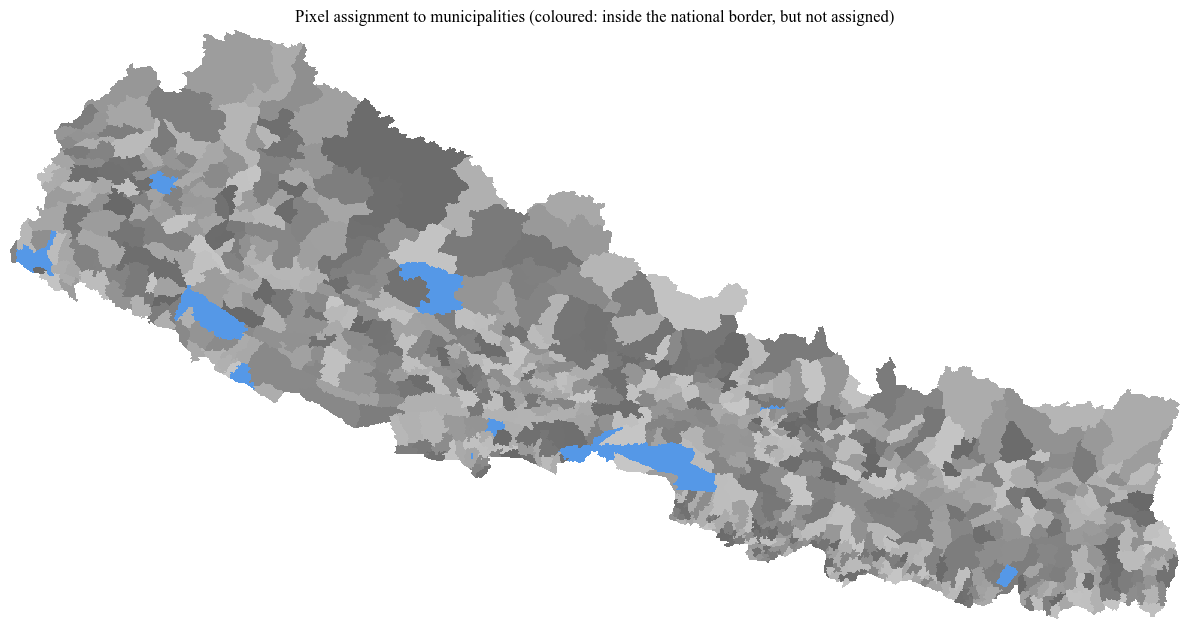

In [6]:
muni_raster = rasterize(
    zip(municipalities.geometry, municipalities["muni_id"]),
    out_shape=grid_shape, transform=grid_transform,
    fill=0, all_touched=False, dtype="int32",
)
border_raster = rasterize(
    ((geom, 1) for geom in border.geometry),
    out_shape=grid_shape, transform=grid_transform,
    fill=0, all_touched=False, dtype="uint8",
).astype(bool)

ids = muni_raster.ravel()
inside_border = border_raster.ravel()
n_pixels_all = np.bincount(ids, minlength=n_muni + 1)   # index 0 = not assigned
n_total = ids.size
n_unassigned = int(n_pixels_all[0])

print(f"Pixels per municipality (sum): {int(n_pixels_all[1:].sum()):>10,}")
print(f"Unassigned pixels:             {n_unassigned:>10,}")
print(f"Sum:                           {int(n_pixels_all.sum()):>10,}")
print(f"Total pixels in grid:          {n_total:>10,}")
assert n_pixels_all.sum() == n_total

print(f"\nPixels inside the national border: {int(inside_border.sum()):,}")
print(f"  of which not assigned to any municipality: {int((inside_border & (ids == 0)).sum()):,}")
print(f"Municipality pixels outside the national border: {int((~inside_border & (ids > 0)).sum()):,}")

no_pixel = municipalities.loc[n_pixels_all[1:] == 0, ["gemeinde", "municipality_type", "province"]]
print(f"\nMunicipalities without a single pixel centre: {len(no_pixel)}")
if len(no_pixel):
    print(no_pixel.to_string(index=False))

# Are valid pixels or school cells lost because they are not assigned to any municipality?
print("\nUnassigned pixels with values (not included in any municipality):")
unassigned = ids == 0
for variant, ok, pred1, osm1 in VARIANT_MASKS:
    print(f"  {variant:5s}: valid {int((ok & unassigned).sum()):,} | pred=1 {int((pred1 & unassigned).sum())} "
          f"| osm=1 {int((osm1 & unassigned).sum())}")

from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(12, 6.5))
shuffled = np.random.default_rng(0).permutation(n_muni + 1)[muni_raster].astype(float)
shuffled[muni_raster == 0] = np.nan
ax.imshow(shuffled, cmap="Greys", vmin=-n_muni, vmax=2 * n_muni, interpolation="nearest")  # light grey shades
gap = np.where(border_raster & (muni_raster == 0), 1.0, np.nan)
ax.imshow(gap, cmap=ListedColormap(["#5598e7"]), interpolation="nearest")
ax.set_title("Pixel assignment to municipalities (coloured: inside the national border, but not assigned)")
ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Metrics per municipality

| Column | Meaning |
|---|---|
| `n_pixels` | assigned pixels of the municipality (independent of NoData, the same for both variants) |
| `n_valid_*` | pixels that are valid in prediction and OSM |
| `pred_pos_*` / `osm_pos_*` | pixels with prediction = 1 / OSM = 1 |
| `CR_*` | `osm_pos / pred_pos` — quantity comparison, not clipped |
| `both_*`, `gap_*`, `osm_only_*`, `overlap_rate_*` | only a **diagnostic** of the spatial agreement, not included in the CR |
| `coverage_*` | `n_valid / n_pixels` — how strongly the municipality is affected by the removed training area (and, for AOA, additionally by the AOA mask) |
| `aoa_share` | `n_valid_aoa / n_valid_nepal` (present only once) |

**CR for `pred_pos = 0`:** division by zero — the CR is then undefined and set to `NaN`. Such municipalities additionally get `flag_no_pred_*`; municipalities with `pred_pos = 0` but `osm_pos > 0` are reported separately, because OSM has schools there although the model expects none.


### 3.1 Computation

In [7]:
def count(mask):
    return np.bincount(ids[mask], minlength=n_muni + 1)[1:]


muni = pd.DataFrame(municipalities[["gemeinde", "name", "name_en", "municipality_type", "province",
                                    "district", "hazard_zone", "muni_id", "osm_id"]])
muni["n_pixels"] = n_pixels_all[1:]

for variant, ok, pred1, osm1 in VARIANT_MASKS:
    n_valid = count(ok)
    pred_pos = count(pred1)
    osm_pos = count(osm1)
    both = count(pred1 & osm1)

    with np.errstate(divide="ignore", invalid="ignore"):
        cr = np.where(pred_pos > 0, osm_pos / pred_pos, np.nan)
        overlap_rate = np.where(osm_pos > 0, both / osm_pos, np.nan)
        coverage = np.where(muni["n_pixels"] > 0, n_valid / muni["n_pixels"], np.nan)

    muni[f"n_valid_{variant}"] = n_valid
    muni[f"pred_pos_{variant}"] = pred_pos
    muni[f"osm_pos_{variant}"] = osm_pos
    muni[f"CR_{variant}"] = cr
    muni[f"both_{variant}"] = both
    muni[f"gap_{variant}"] = count(pred1 & ~osm1)        # Prediction = 1, OSM = 0
    muni[f"osm_only_{variant}"] = count(osm1 & ~pred1)   # Prediction = 0, OSM = 1
    muni[f"overlap_rate_{variant}"] = overlap_rate
    muni[f"coverage_{variant}"] = coverage
    muni[f"flag_empty_{variant}"] = n_valid == 0
    muni[f"flag_partial_{variant}"] = coverage < 0.5
    muni[f"flag_no_pred_{variant}"] = pred_pos == 0

# AOA is a subset of all Nepal: no municipality may have more valid pixels there
assert (muni["n_valid_aoa"] <= muni["n_valid_nepal"]).all()
muni["aoa_share"] = muni["n_valid_aoa"] / muni["n_valid_nepal"].where(muni["n_valid_nepal"] > 0)


def variant_view(variant):
    # Columns of one variant without suffix (pred_pos_aoa -> pred_pos), for 3.4 and 4
    suffix = f"_{variant}"
    cols = [c for c in muni.columns if c.endswith(suffix)]
    base = ["gemeinde", "municipality_type", "province", "district", "hazard_zone", "n_pixels", "aoa_share"]
    return muni[base + cols].rename(columns=lambda c: c.removesuffix(suffix))


# Check: sums over municipalities vs. raster totals (difference = pixels without municipality, 2.4)
check = pd.DataFrame(
    {"raster_total": [int(pred1_nepal.sum()), int(osm1_nepal.sum()), int(pred1_aoa.sum()), int(osm1_aoa.sum())]},
    index=["pred_pos_nepal", "osm_pos_nepal", "pred_pos_aoa", "osm_pos_aoa"],
)
check["summe_gemeinden"] = [int(muni[col].sum()) for col in check.index]
check["ohne_gemeinde"] = check["raster_total"] - check["summe_gemeinden"]
print(check.to_string())

print("\nFlags (number of municipalities):")
print(muni.filter(like="flag_").sum().to_string())

# Excerpt: the 10 municipalities with the most predicted cells (all Nepal)
show = ["gemeinde", "municipality_type", "province",
        "pred_pos_nepal", "osm_pos_nepal", "CR_nepal",
        "pred_pos_aoa", "osm_pos_aoa", "CR_aoa", "aoa_share"]
muni.sort_values("pred_pos_nepal", ascending=False)[show].head(10).style.hide(axis="index").format(precision=2)

                raster_total  summe_gemeinden  ohne_gemeinde
pred_pos_nepal         11900            11726            174
osm_pos_nepal          19224            19017            207
pred_pos_aoa            7649             7618             31
osm_pos_aoa            12682            12640             42

Flags (number of municipalities):
flag_empty_nepal       42
flag_partial_nepal     46
flag_no_pred_nepal     72
flag_empty_aoa         42
flag_partial_aoa       58
flag_no_pred_aoa      107


gemeinde,municipality_type,province,pred_pos_nepal,osm_pos_nepal,CR_nepal,pred_pos_aoa,osm_pos_aoa,CR_aoa,aoa_share
Bharatpur,Metropolitan City,Bagmati,125,142,1.14,15,19,1.27,0.56
Baglung,Urban Municipality,Gandaki,107,74,0.69,84,51,0.61,0.89
Birendranagar,Urban Municipality,Karnali,106,104,0.98,34,54,1.59,0.91
Itahari,Sub-Metropolitan City,Koshi,93,18,0.19,16,0,0.00,0.38
Dharan,Sub-Metropolitan City,Koshi,87,38,0.44,9,10,1.11,0.84
Kalaiya,Sub-Metropolitan City,Madhesh,84,95,1.13,23,34,1.48,0.76
Birgunj,Metropolitan City,Madhesh,82,122,1.49,5,16,3.20,0.51
Beni,Urban Municipality,Gandaki,77,63,0.82,68,50,0.74,0.94
Hetauda,Sub-Metropolitan City,Bagmati,76,94,1.24,26,50,1.92,0.85
Nilakantha,Urban Municipality,Bagmati,74,96,1.30,61,80,1.31,0.96


### 3.2 Exclude municipalities in the training area

**46 municipalities** lie (almost) entirely within the training area and are excluded.

Municipalities in the list: 46 | found in muni: 46
Identical to the rule 'less than 50% valid area': True
Cells in the excluded municipalities: valid 6, pred=1 1, osm=1 0

Excluded municipalities (46), alphabetical:
                        gemeinde province  municipality_type hazard_zone
                       Adanchuli  Karnali Rural Municipality    moderate
          Bhaktapur Municipality  Bagmati Urban Municipality         low
     Budhanilkantha Municipality  Bagmati Urban Municipality        high
        Chandragiri Municipality  Bagmati Urban Municipality        high
      Changunarayan Municipality  Bagmati Urban Municipality         low
                       Chankheli  Karnali Rural Municipality    moderate
                Chharka Tangsong  Karnali Rural Municipality         low
        Dakshinkali Municipality  Bagmati Urban Municipality        high
                    Dolpo Buddha  Karnali Rural Municipality         low
                        Godawari  Bagmati Urban Munici

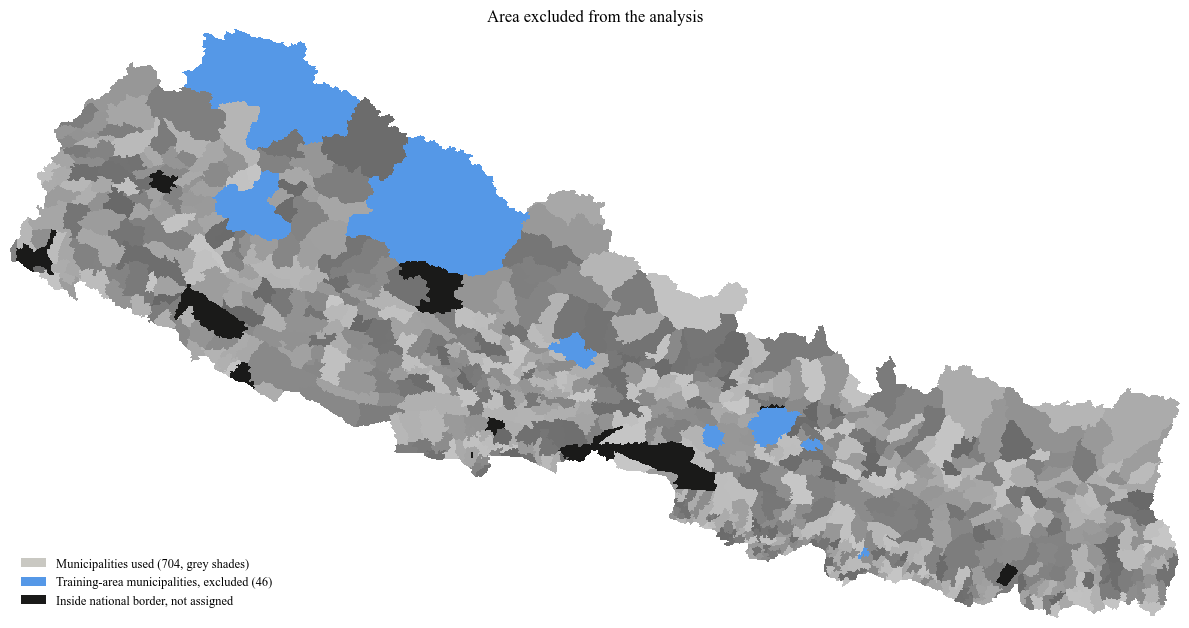


Municipalities from here on: 704


In [8]:
excluded_path = f"{data_dir}\\training_region\\excluded_municipalities.csv"
excluded_ids = set(pd.read_csv(excluded_path)["osm_id"])
muni["flag_training_area"] = muni["osm_id"].isin(excluded_ids)

# Checks
not_found = excluded_ids - set(muni["osm_id"])
print(f"Municipalities in the list: {len(excluded_ids)} | found in muni: {len(excluded_ids) - len(not_found)}")
matches_rule = (muni["flag_training_area"] == (muni["coverage_nepal"] < 0.5)).all()
print(f"Identical to the rule 'less than 50% valid area': {matches_rule}")
if not matches_rule:
    print(muni.loc[muni["flag_training_area"] != (muni["coverage_nepal"] < 0.5),
                   ["gemeinde", "district", "coverage_nepal", "flag_training_area"]].to_string(index=False))

excluded = muni[muni["flag_training_area"]]
print(f"Cells in the excluded municipalities: valid {int(excluded['n_valid_nepal'].sum())}, "
      f"pred=1 {int(excluded['pred_pos_nepal'].sum())}, osm=1 {int(excluded['osm_pos_nepal'].sum())}")

print(f"\nExcluded municipalities ({len(excluded)}), alphabetical:")
print(excluded.sort_values("gemeinde")[["gemeinde", "province", "municipality_type", "hazard_zone"]]
      .to_string(index=False))

print("\nThe same municipalities by district, hazard zone and type:")
print(excluded.groupby(["district", "hazard_zone", "municipality_type"]).size().rename("gemeinden").to_string())

# --- Map: what is dropped? (same display as in 2.4, plus training-area municipalities) ---
from matplotlib.patches import Patch

GAP_COLOR = "#1a1a19"
excluded_pixels = np.isin(muni_raster, excluded[["muni_id"]].to_numpy())
gap_pixels = border_raster & (muni_raster == 0)        # inside the national border, but not assigned to any municipality

fig, ax = plt.subplots(figsize=(12, 6.5))
# Municipalities in graded grey shades (as in 2.4), so that the individual municipalities remain recognisable
shuffled = np.random.default_rng(0).permutation(n_muni + 1)[muni_raster].astype(float)
shuffled[muni_raster == 0] = np.nan
ax.imshow(shuffled, cmap="Greys", vmin=-n_muni, vmax=2 * n_muni, interpolation="nearest")
for mask, color in [(excluded_pixels, THEME), (gap_pixels, GAP_COLOR)]:
    ax.imshow(np.where(mask, 1.0, np.nan), cmap=ListedColormap([color]), interpolation="nearest")

ax.legend(handles=[Patch(facecolor="#c9c8c2", label=f"Municipalities used ({len(muni) - len(excluded):,}, grey shades)"),
                   Patch(facecolor=THEME, label=f"Training-area municipalities, excluded ({len(excluded)})"),
                   Patch(facecolor=GAP_COLOR, label="Inside national border, not assigned")],
          loc="lower left", frameon=False, fontsize=9)
ax.set_title("Area excluded from the analysis")
ax.axis("off")
plt.tight_layout(); plt.show()

muni = muni[~muni["flag_training_area"]].reset_index(drop=True)
print(f"\nMunicipalities from here on: {len(muni)}")

### 3.3 How small are the denominators? Distribution of `pred_pos` and `osm_pos`

             pred_pos_nepal  osm_pos_nepal  pred_pos_aoa  osm_pos_aoa
n_gemeinden          704.00         704.00        704.00       704.00
= 0                   27.00          59.00         62.00       100.00
1–9                  265.00         181.00        353.00       236.00
>= 10                412.00         464.00        289.00       368.00
mean                  16.65          27.01         10.82        17.95
q0                     0.00           0.00          0.00         0.00
q10                    3.00           1.00          1.00         0.00
q25                    5.00           4.00          3.00         2.00
q50                   12.00          24.00          7.00        11.00
q75                   22.00          43.00         15.00        32.00
q90                   35.00          57.00         26.00        46.00
q95                   52.00          70.00         32.85        52.85
q99                   76.97          96.00         50.00        70.97
q100                

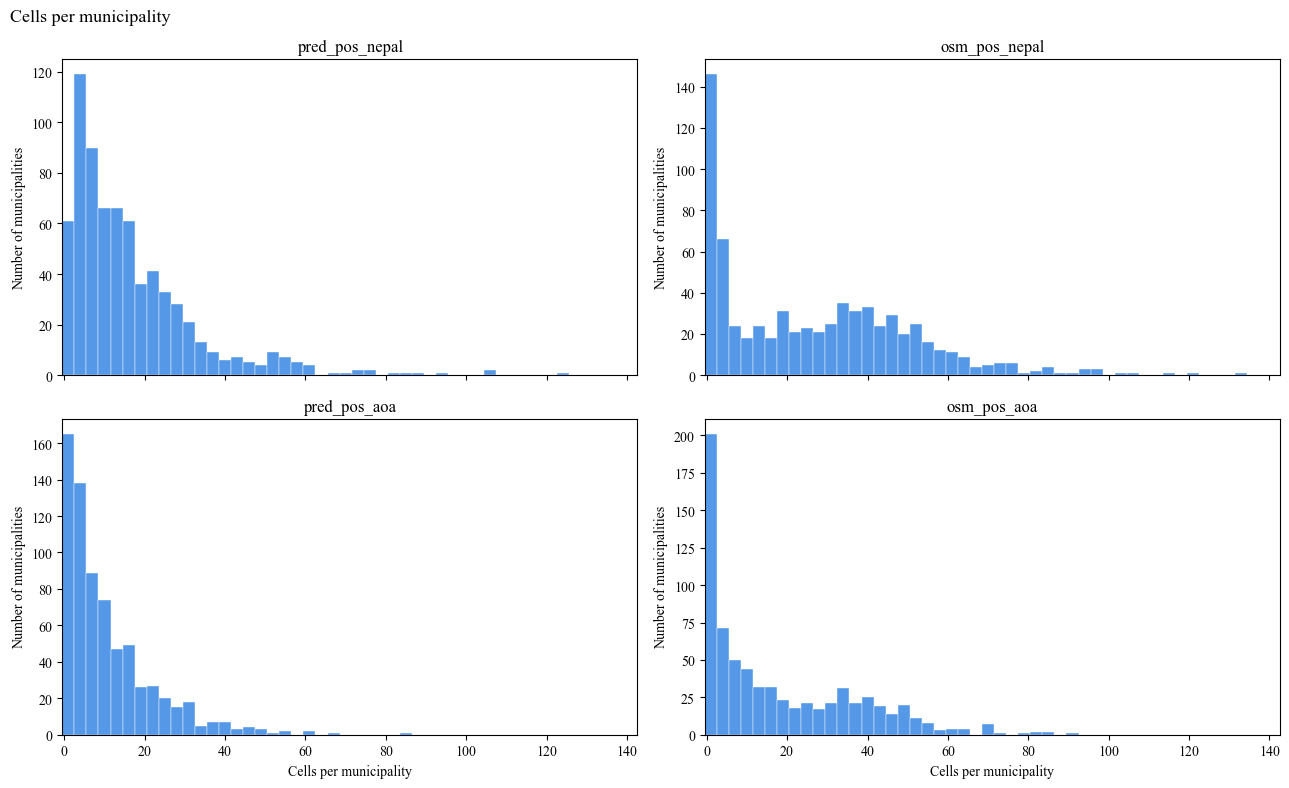

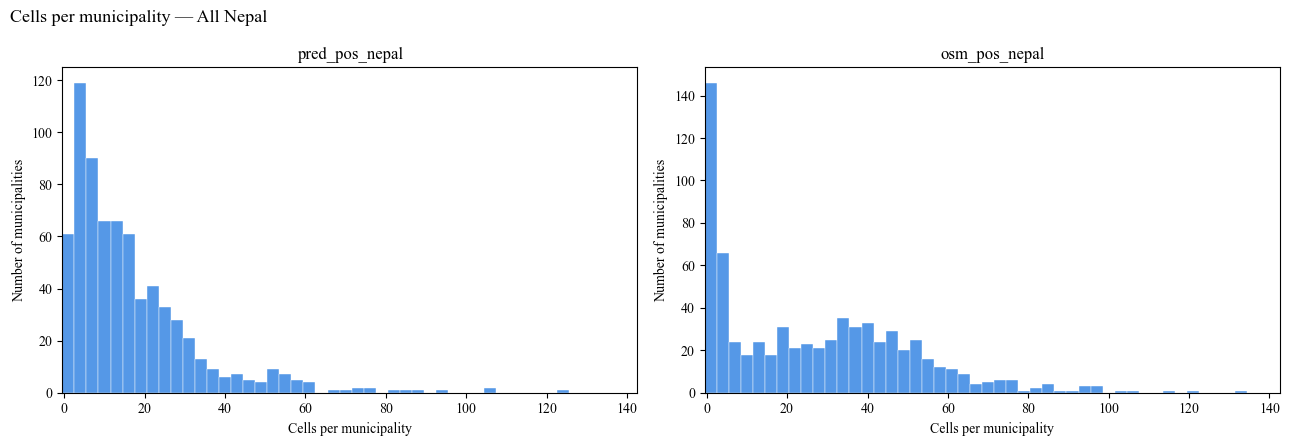

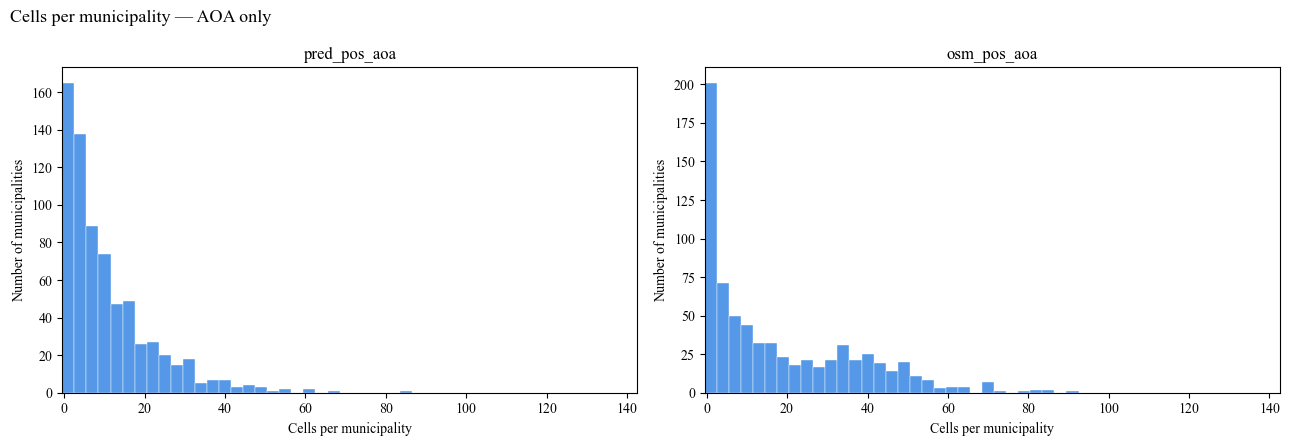

In [9]:
QUANTILES = [0, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
COUNT_COLS = ["pred_pos_nepal", "osm_pos_nepal", "pred_pos_aoa", "osm_pos_aoa"]


def count_summary(s):
    return pd.Series({"n_gemeinden": len(s), "= 0": int((s == 0).sum()),
                      "1–9": int(((s >= 1) & (s < 10)).sum()), ">= 10": int((s >= 10).sum()),
                      "mean": s.mean(), **{f"q{int(q * 100)}": s.quantile(q) for q in QUANTILES}})


summary_counts = pd.DataFrame({col: count_summary(muni[col]) for col in COUNT_COLS})
print(summary_counts.round(2).to_string())

# Shared x-axis and shared bin width, so that the four panels are comparable
x_max = int(muni[COUNT_COLS].to_numpy().max())
step = max(1, int(np.ceil((x_max + 1) / 60)))
bins = np.arange(-0.5, x_max + 1.5, step)



def plot_count_hist(ax, col):
    ax.hist(muni[col], bins=bins, color=THEME, edgecolor="white", linewidth=0.3)
    ax.set_xlim(-0.5, x_max + 0.5)
    ax.set_title(col)
    ax.set_ylabel("Number of municipalities")


# Both variants: all Nepal at the top, AOA at the bottom
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, col in zip(axes.flat, COUNT_COLS):
    plot_count_hist(ax, col)
for ax in axes[1]:   # axis label only below the bottom row (sharex hides the ticks at the top)
    ax.set_xlabel("Cells per municipality")
fig.suptitle("Cells per municipality", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

# Each variant separately
for variant in VARIANTS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
    for ax, col in zip(axes, [f"pred_pos_{variant}", f"osm_pos_{variant}"]):
        plot_count_hist(ax, col)
        ax.set_xlabel("Cells per municipality")
    fig.suptitle(f"Cells per municipality — {VARIANT_LABELS[variant]}", x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    plt.show()

### 3.4 Distribution of the CR

CR > 1 means: OSM has more school cells in the municipality than the model expects. These values are not clipped. The breakdown table assigns each municipality to exactly one subgroup.

===== nepal =====
                        gemeinden  anteil_total_pct  anteil_obergruppe_pct  pred_pos_summe  osm_pos_summe  CR_pooled
Total                         704             100.0                  100.0           11725          19017       1.62
mit CR (pred_pos > 0)         677              96.2                   96.2           11725          18687       1.59
    CR > 1                    406              57.7                   60.0            6534          16605       2.54
    CR = 1                     12               1.7                    1.8             117            117       1.00
    0 < CR < 1                203              28.8                   30.0            4500           1965       0.44
    CR = 0                     56               8.0                    8.3             574              0       0.00
ohne CR (pred_pos = 0)         27               3.8                    3.8               0            330        NaN
    osm_pos > 0                24             

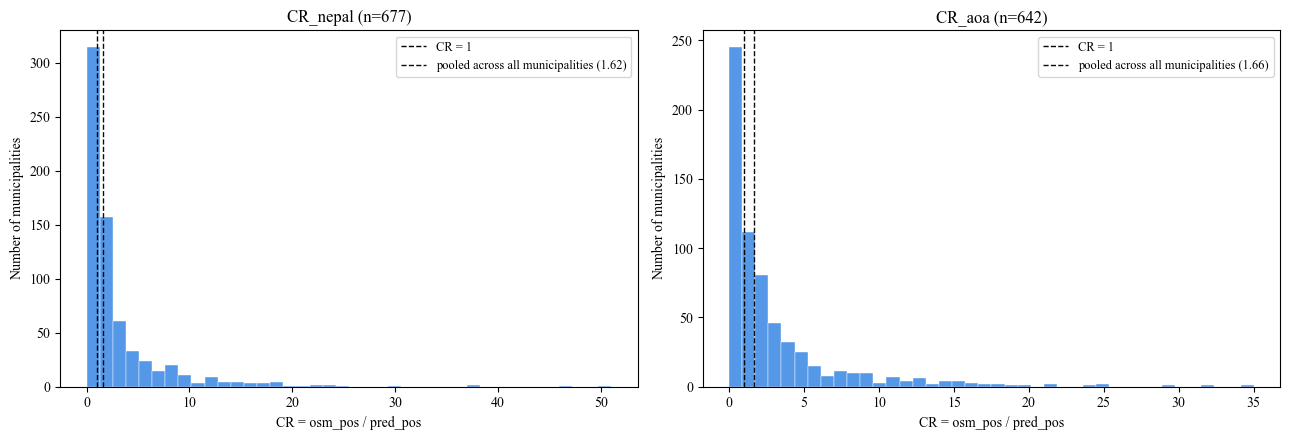

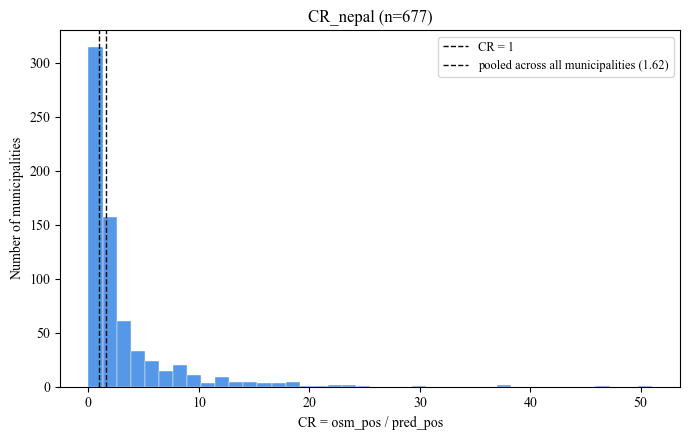

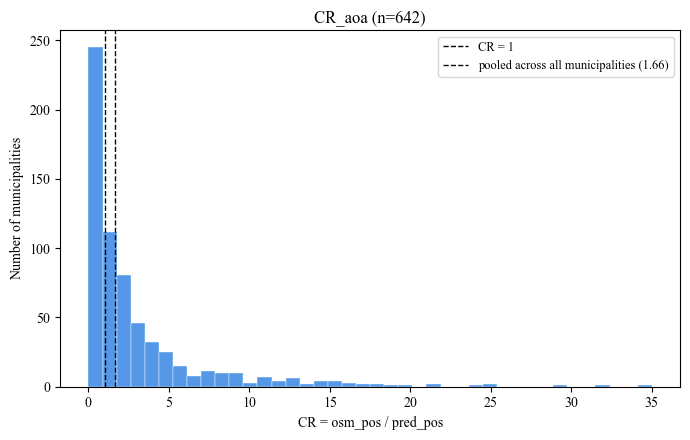

In [10]:
LIST_COLS = ["gemeinde", "municipality_type", "province", "pred_pos", "osm_pos", "CR",
             "overlap_rate", "coverage", "flag_partial"]

def cr_breakdown(df):
    # Complete breakdown of all municipalities: each municipality falls into exactly one subgroup.
    has_pred = df["pred_pos"] > 0
    has_osm = df["osm_pos"] > 0
    all_ = pd.Series(True, index=df.index)
    groups = [  # (row, mask, parent group)
        ("Total", all_, all_),
        ("mit CR (pred_pos > 0)", has_pred, all_),
        ("    CR > 1", has_pred & (df["CR"] > 1), has_pred),
        ("    CR = 1", has_pred & (df["CR"] == 1), has_pred),
        ("    0 < CR < 1", has_pred & (df["CR"] > 0) & (df["CR"] < 1), has_pred),
        ("    CR = 0", has_pred & (df["CR"] == 0), has_pred),
        ("ohne CR (pred_pos = 0)", ~has_pred, all_),
        ("    osm_pos > 0", ~has_pred & has_osm, ~has_pred),
        ("    osm_pos = 0", ~has_pred & ~has_osm, ~has_pred),
    ]
    rows = []
    for label, mask, parent in groups:
        pred_sum, osm_sum = int(df.loc[mask, "pred_pos"].sum()), int(df.loc[mask, "osm_pos"].sum())
        rows.append({
            "": label,
            "gemeinden": int(mask.sum()),
            "anteil_total_pct": 100 * mask.sum() / len(df),
            "anteil_obergruppe_pct": 100 * mask.sum() / parent.sum(),
            "pred_pos_summe": pred_sum,
            "osm_pos_summe": osm_sum,
            "CR_pooled": osm_sum / pred_sum if pred_sum > 0 else np.nan,
        })
    return pd.DataFrame(rows).set_index("").rename_axis(None)


cr_summary = {}
for variant in VARIANTS:
    df = variant_view(variant)
    defined = df["CR"].notna()
    above = df[df["CR"] > 1].sort_values("CR", ascending=False)

    print(f"===== {variant} =====")
    breakdown = cr_breakdown(df)
    assert breakdown.loc["Total", "gemeinden"] == breakdown.loc["mit CR (pred_pos > 0)", "gemeinden"] \
        + breakdown.loc["ohne CR (pred_pos = 0)", "gemeinden"]
    print(breakdown.round({"anteil_total_pct": 1, "anteil_obergruppe_pct": 1, "CR_pooled": 2}).to_string())
    print("\nMunicipalities with CR > 1:")
    print(above[LIST_COLS].round(3).to_string(index=False))
    print()

    cr_summary[f"CR_{variant}"] = pd.Series({
        "n_CR": int(defined.sum()), "mean": df["CR"].mean(), "std": df["CR"].std(),
        **{f"q{int(q * 100)}": df["CR"].quantile(q) for q in QUANTILES}})

print("Distribution of the CR (municipalities with pred_pos > 0):")
print(pd.DataFrame(cr_summary).round(3).to_string())



def plot_cr_hist(ax, variant):
    df = variant_view(variant)
    cr_pooled = df["osm_pos"].sum() / df["pred_pos"].sum()
    ax.hist(df["CR"].dropna(), bins=40, color=THEME, edgecolor="white", linewidth=0.3)
    ax.axvline(1, ls="--", color="black", lw=1, label="CR = 1")
    ax.axvline(cr_pooled, ls="--", color="#0b0b0b", lw=1, label=f"pooled across all municipalities ({cr_pooled:.2f})")
    ax.set_title(f"CR_{variant} (n={int(df['CR'].notna().sum())})")
    ax.set_xlabel("CR = osm_pos / pred_pos"); ax.set_ylabel("Number of municipalities")
    ax.legend()


# Both variants side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, variant in zip(axes, VARIANTS):
    plot_cr_hist(ax, variant)
plt.tight_layout(); plt.show()

# Each variant separately
for variant in VARIANTS:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    plot_cr_hist(ax, variant)
    plt.tight_layout(); plt.show()

## 4. Aggregation by province, municipality type and hazard zone

| Column | Meaning |
|---|---|
| `n_gemeinden` | municipalities in the group (incl. those without a defined CR) |
| `aoa_share_mean` | mean of `aoa_share` over the municipalities |
| `pred_pos_total`, `osm_pos_total` | sums over the municipalities |
| `CR_pooled` | `osm_pos_total / pred_pos_total` — implicitly weighted by `pred_pos`, large municipalities dominate, robust to small denominators |
| `CR_ci_low`, `CR_ci_high` | 95% bootstrap interval of `CR_pooled`: the municipalities of the group are resampled 2000 times with replacement and `CR_pooled` is recomputed each time; the interval covers the middle 95% of these values. It shows how strongly `CR_pooled` depends on which municipalities happen to be in the group — wide for few municipalities or when single municipalities dominate the sum. |
| `CR_mean`, `CR_median`, `CR_std`, `n_CR` | over the municipality CRs; each municipality counts equally; `n_CR` = municipalities with a defined CR |
| `CR_index` | `CR_pooled / max(CR_pooled)` over the groups of this stratification |
| `rang` | rank by `CR_pooled`, descending: **rank 1 = highest CR** = most OSM schools relative to the model expectation (best coverage) |

In [11]:
N_BOOT = 2000
CI_LEVEL = 95


def bootstrap_cr_pooled(df, n_boot=N_BOOT, level=CI_LEVEL, seed=42):
    # Resample the municipalities of the group with replacement and recompute CR_pooled each time.
    # The middle 95% of these values form the interval. Draws without any
    # predicted cell (CR undefined) are skipped.
    rng = np.random.default_rng(seed)
    pred, osm = df["pred_pos"].to_numpy(), df["osm_pos"].to_numpy()
    idx = rng.integers(0, len(df), size=(n_boot, len(df)))
    pred_b, osm_b = pred[idx].sum(axis=1), osm[idx].sum(axis=1)
    cr_b = osm_b[pred_b > 0] / pred_b[pred_b > 0]
    if len(cr_b) == 0:
        return np.nan, np.nan
    tail = (100 - level) / 2
    return tuple(np.percentile(cr_b, [tail, 100 - tail]))


def group_stats(df):
    pred_total, osm_total = df["pred_pos"].sum(), df["osm_pos"].sum()
    ci_low, ci_high = bootstrap_cr_pooled(df)
    return pd.Series({
        "n_gemeinden": len(df),
        "aoa_share_mean": df["aoa_share"].mean(),
        "pred_pos_total": int(pred_total),
        "osm_pos_total": int(osm_total),
        "CR_pooled": osm_total / pred_total if pred_total > 0 else np.nan,
        "CR_ci_low": ci_low,
        "CR_ci_high": ci_high,
        "CR_mean": df["CR"].mean(),
        "CR_median": df["CR"].median(),
        "CR_std": df["CR"].std(),
        "n_CR": int(df["CR"].notna().sum()),
    })


def aggregate(variant, by, order=None):
    # order: fixed order of the groups (e.g. hazard levels); otherwise sorted by rank
    df = variant_view(variant)
    out = pd.DataFrame({group: group_stats(g) for group, g in df.groupby(by)}).T
    max_cr = out["CR_pooled"].max()
    out["CR_index"] = out["CR_pooled"] / max_cr
    out["rang"] = out["CR_pooled"].rank(method="min", ascending=False)   # rank 1 = highest CR
    if order is None:
        out = out.sort_values(["rang", "CR_pooled"])
    else:
        out = out.reindex([group for group in order if group in out.index])

    # Reference 1: all municipalities together
    ref = group_stats(df)
    ref["CR_index"] = ref["CR_pooled"] / max_cr
    out.loc["Nepal (alle Gemeinden)"] = ref

    # Reference 2: all valid pixels, incl. those without a municipality (2.4) -- counts only
    pred_all = check.loc[f"pred_pos_{variant}", "raster_total"]
    osm_all = check.loc[f"osm_pos_{variant}", "raster_total"]
    out.loc["Nepal (alle Pixel)", ["pred_pos_total", "osm_pos_total", "CR_pooled", "CR_index"]] = \
        [pred_all, osm_all, osm_all / pred_all, osm_all / pred_all / max_cr]

    for col in ["n_gemeinden", "pred_pos_total", "osm_pos_total", "n_CR", "rang"]:
        out[col] = out[col].astype("Int64")
    out.index.name = by
    return out


agg_province_nepal = aggregate("nepal", "province")
agg_type_nepal = aggregate("nepal", "municipality_type")
agg_province_aoa = aggregate("aoa", "province")
agg_type_aoa = aggregate("aoa", "municipality_type")
agg_hazard_nepal = aggregate("nepal", "hazard_zone", order=zone_order)
agg_hazard_aoa = aggregate("aoa", "hazard_zone", order=zone_order)

for title, table in [("All Nepal — by province", agg_province_nepal),
                     ("All Nepal — by municipality type", agg_type_nepal),
                     ("All Nepal — by hazard zone", agg_hazard_nepal),
                     ("AOA only — by province", agg_province_aoa),
                     ("AOA only — by municipality type", agg_type_aoa),
                     ("AOA only — by hazard zone", agg_hazard_aoa)]:
    print(f"===== {title} =====")
    print(table.round(3).to_string())
    print()

===== All Nepal — by province =====
                        n_gemeinden  aoa_share_mean  pred_pos_total  osm_pos_total  CR_pooled  CR_ci_low  CR_ci_high  CR_mean  CR_median  CR_std  n_CR  CR_index  rang
province                                                                                                                                                              
Lumbini                         106           0.881            1607           4776      2.972      2.510       3.571    6.722      4.286   7.785   103     1.000     1
Bagmati                          99           0.950            1987           4427      2.228      1.906       2.618    4.437      2.407   5.178    98     0.750     2
Sudurpashchim                    88           0.923            1326           2342      1.766      1.411       2.178    3.386      1.477   6.011    86     0.594     3
Madhesh                         135           0.796            1989           2859      1.437      1.253       1.652    2.128    

### 4.1 Figure: CR by province, municipality type and hazard zone

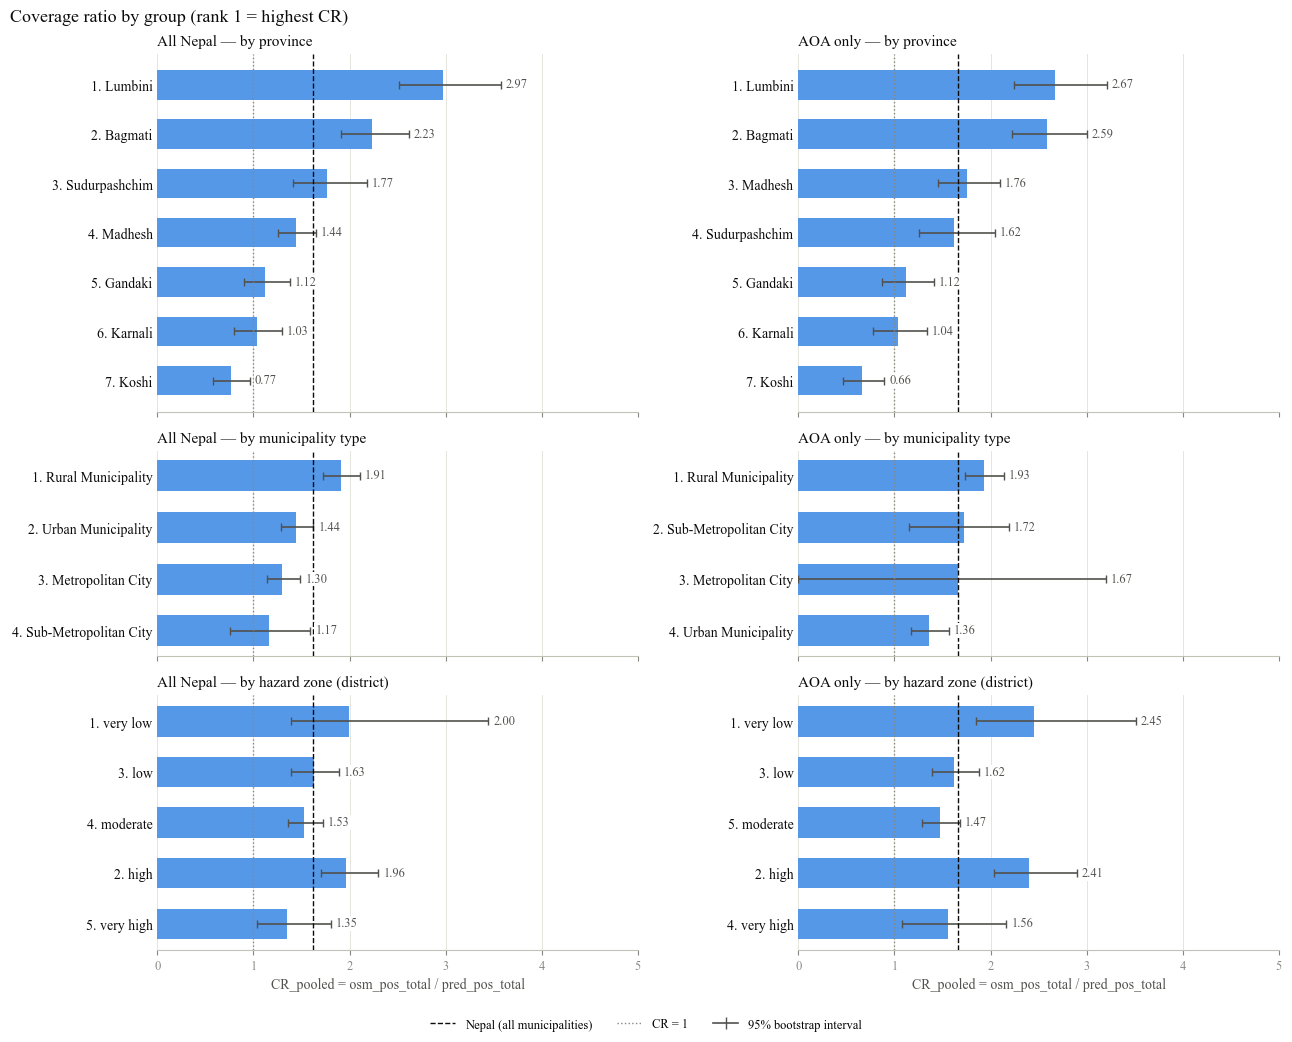

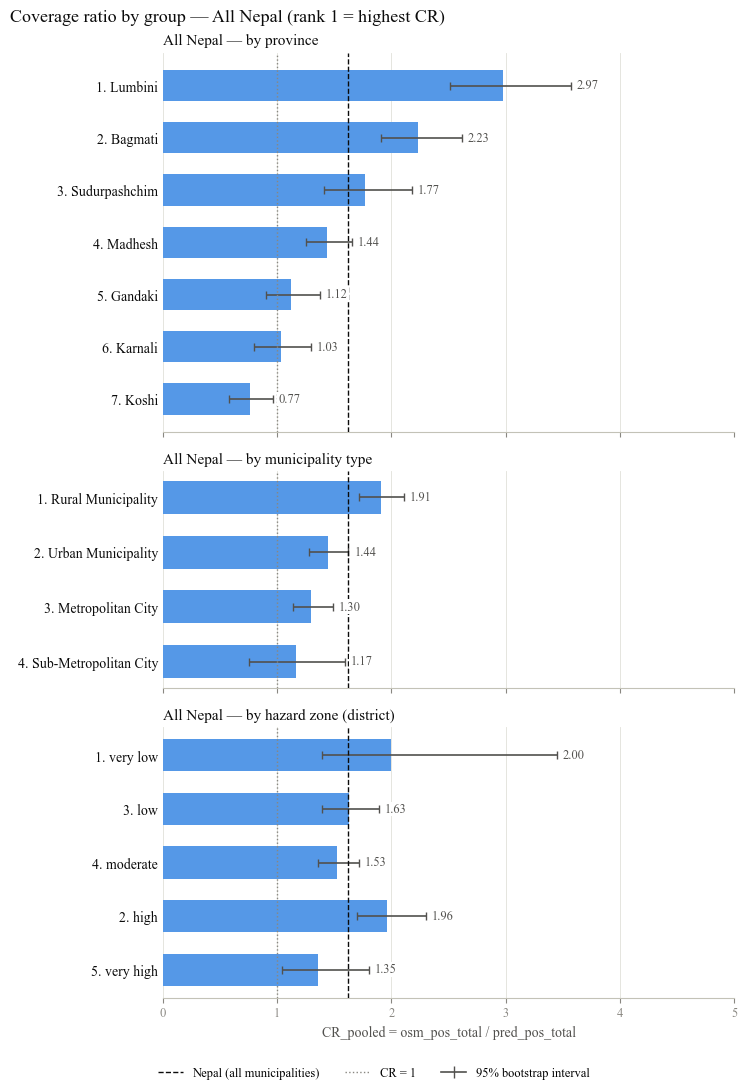

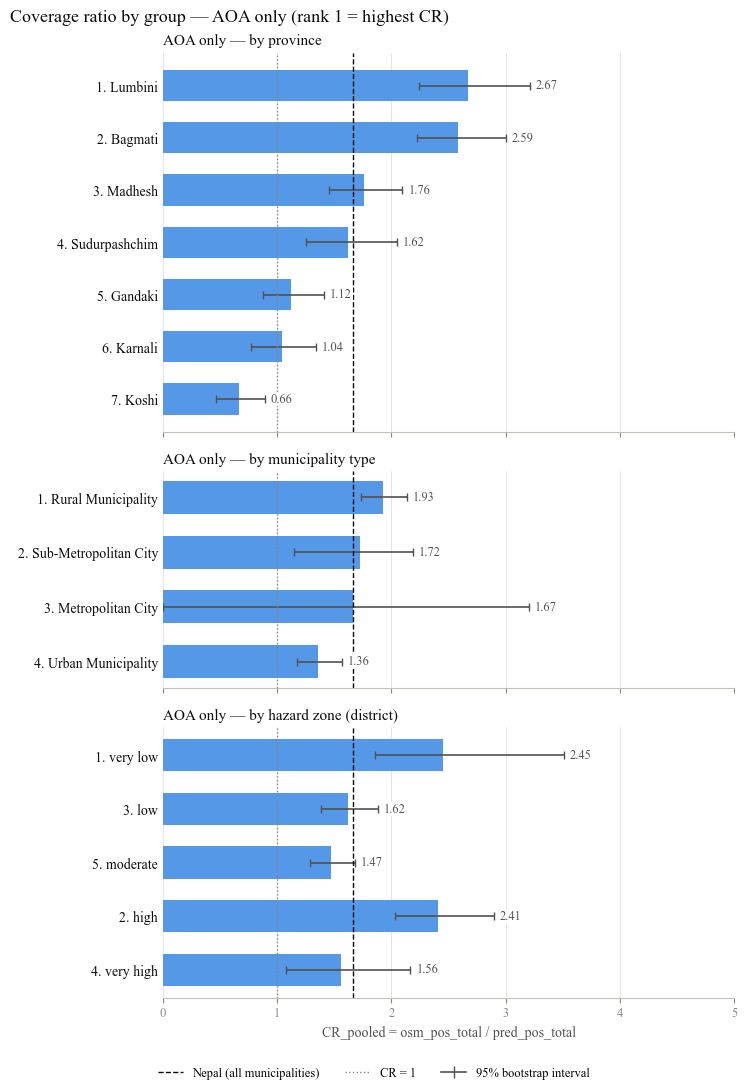

In [ ]:
BAR_COLOR = "#5598e7"
INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
REFERENCE_ROWS = ["Nepal (alle Gemeinden)", "Nepal (alle Pixel)"]
LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1)

panels = [("All Nepal — by province", agg_province_nepal),
          ("AOA only — by province", agg_province_aoa),
          ("All Nepal — by municipality type", agg_type_nepal),
          ("AOA only — by municipality type", agg_type_aoa),
          ("All Nepal — by hazard zone (district)", agg_hazard_nepal),
          ("AOA only — by hazard zone (district)", agg_hazard_aoa)]
X_MAX = 5



def plot_cr_panel(ax, title, table):
    groups = table.drop(index=REFERENCE_ROWS)
    national = table.loc["Nepal (alle Gemeinden)", "CR_pooled"]
    y = np.arange(len(groups))[::-1]

    ax.barh(y, groups["CR_pooled"].fillna(0), height=0.6, color=BAR_COLOR, zorder=2)
    clipped = groups["CR_ci_high"] > X_MAX
    ci_high_shown = groups["CR_ci_high"].clip(upper=X_MAX)
    ax.errorbar(groups["CR_pooled"], y,
                xerr=[groups["CR_pooled"] - groups["CR_ci_low"], ci_high_shown - groups["CR_pooled"]],
                fmt="none", ecolor=INK_SECONDARY, elinewidth=1.2, capsize=3, zorder=3)
    if clipped.any():
        ax.plot([X_MAX] * clipped.sum(), y[clipped.to_numpy()], ">", color=INK_SECONDARY,
                markersize=6, clip_on=False, zorder=3)
    for yi, (group, row) in zip(y, groups.iterrows()):
        if pd.isna(row["CR_pooled"]):
            ax.text(0.03, yi, "no predicted cell", va="center", fontsize=9, color=MUTED,
                    bbox=LABEL_BOX, zorder=4)
        elif row["CR_ci_high"] > X_MAX:
            ax.text(X_MAX - 0.15, yi - 0.5, f"{row['CR_pooled']:.2f}   (interval up to {row['CR_ci_high']:.1f})",
                    ha="right", va="center", fontsize=9, color=INK_SECONDARY, bbox=LABEL_BOX, zorder=4)
        else:
            ax.text(row["CR_ci_high"] + 0.05, yi, f"{row['CR_pooled']:.2f}", va="center",
                    fontsize=9, color=INK_SECONDARY, bbox=LABEL_BOX, zorder=4)

    labels = [f"{rang}. {group}" if pd.notna(rang) else f"–  {group}"
              for group, rang in zip(groups.index, groups["rang"])]
    ax.set_yticks(y, labels, fontsize=10, color=INK)

    ax.axvline(1, color=MUTED, lw=1, ls=":", zorder=3)
    ax.axvline(national, color=INK, lw=1, ls="--", zorder=3)

    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlim(0, X_MAX)
    ax.grid(axis="x", color=GRID, lw=0.6, zorder=0)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")


def finish_figure(fig, axes, suptitle):
    for ax in axes:
        ax.set_xlabel("CR_pooled = osm_pos_total / pred_pos_total", color=INK_SECONDARY, fontsize=10)
    fig.legend(handles=[Line2D([], [], color=INK, lw=1, ls="--", label="Nepal (all municipalities)"),
                        Line2D([], [], color=MUTED, lw=1, ls=":", label="CR = 1"),
                        Line2D([], [], color=INK_SECONDARY, lw=1.2, marker="|", markersize=8,
                               label=f"{CI_LEVEL}% bootstrap interval"),],
               loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()


fig, axes = plt.subplots(3, 2, figsize=(13, 10.5), sharex=True, gridspec_kw={"height_ratios": [7, 4, 5]})
for ax, (title, table) in zip(axes.flat, panels):
    plot_cr_panel(ax, title, table)
finish_figure(fig, axes[-1], "Coverage ratio by group (rank 1 = highest CR)")

for k, variant in enumerate(VARIANTS):
    fig, axes = plt.subplots(3, 1, figsize=(7.5, 11), sharex=True, gridspec_kw={"height_ratios": [7, 4, 5]})
    for ax, (title, table) in zip(axes, panels[k::2]):
        plot_cr_panel(ax, title, table)
    finish_figure(fig, axes[-1:], f"Coverage ratio by group — {VARIANT_LABELS[variant]} (rank 1 = highest CR)")

### 4.2 Spread within the groups: are the municipalities similar?

Unlike the municipality CR, D includes *all* municipalities, also those without a predicted cell but with an OSM school (`pred_pos = 0`, `osm_pos > 0`).

In [13]:
def dissimilarity(pred, osm):
    # D = ½ · Σ |share of OSM cells − share of predicted cells| over the municipalities
    if pred.sum() == 0 or osm.sum() == 0:
        return np.nan
    return 0.5 * np.abs(osm / osm.sum() - pred / pred.sum()).sum()


def spread_row(grouping, group, in_group):
    row = {"gruppierung": grouping, "gruppe": group, "n_gemeinden": int(in_group.sum())}
    for variant in VARIANTS:
        pred = muni.loc[in_group, f"pred_pos_{variant}"].to_numpy(float)
        osm = muni.loc[in_group, f"osm_pos_{variant}"].to_numpy(float)
        row[f"D_{variant}"] = dissimilarity(pred, osm)
    return row


rows = []
for grouping, by, agg_table in [("Provinz", "province", agg_province_nepal),
                                ("Gemeindetyp", "municipality_type", agg_type_nepal),
                                ("Gefahrenzone", "hazard_zone", agg_hazard_nepal)]:
    for group in agg_table.index.drop(REFERENCE_ROWS):   # same order as in 4
        rows.append(spread_row(grouping, group, muni[by] == group))
rows.append(spread_row("Referenz", "Nepal (alle Gemeinden)", pd.Series(True, index=muni.index)))

spread = pd.DataFrame(rows)
spread.style.hide(axis="index").format(precision=2)

gruppierung,gruppe,n_gemeinden,D_nepal,D_aoa
Provinz,Lumbini,106,0.35,0.34
Provinz,Bagmati,99,0.31,0.31
Provinz,Sudurpashchim,88,0.42,0.45
Provinz,Madhesh,135,0.32,0.41
Provinz,Gandaki,84,0.39,0.43
Provinz,Karnali,55,0.33,0.38
Provinz,Koshi,137,0.49,0.60
Gemeindetyp,Rural Municipality,436,0.42,0.42
Gemeindetyp,Urban Municipality,251,0.37,0.40
Gemeindetyp,Metropolitan City,3,0.06,0.22


### 4.3 Kruskal-Wallis test

In [14]:
def kruskal_test(values, groups):
    # Kruskal-Wallis test (like kruskal.test in R)
    samples = [v.dropna().to_numpy() for _, v in values.groupby(groups)]
    samples = [s for s in samples if len(s) > 0]
    h, p = kruskal(*samples)
    return {"n": sum(len(s) for s in samples), "chi_squared": h, "df": len(samples) - 1, "p_value": p}


rows = []
for grouping in ["province", "municipality_type", "hazard_zone"]:
    row = {"gruppierung": grouping}
    for variant in VARIANTS:
        result = kruskal_test(muni[f"CR_{variant}"], muni[grouping])
        row.update({f"{key}_{variant}": value for key, value in result.items()})
    rows.append(row)

kruskal_wallis = pd.DataFrame(rows).set_index("gruppierung")
kruskal_wallis.style.format({f"{col}_{variant}": fmt for variant in VARIANTS
                             for col, fmt in [("chi_squared", "{:.4f}"), ("p_value", "{:.3g}")]})

,n_nepal,chi_squared_nepal,df_nepal,p_value_nepal,n_aoa,chi_squared_aoa,df_aoa,p_value_aoa
gruppierung,,,,,,,,
province,677,183.2427,6,6.95e-37,642,178.1545,6,8.37e-36
municipality_type,672,0.3327,3,0.954,637,1.0182,3,0.797
hazard_zone,677,15.7743,4,0.00334,642,25.2759,4,4.43e-05


### 4.4 Spatial autocorrelation: Moran's I

In [ ]:
# Queen neighbourhood
muni_geoms = (municipalities.set_index("osm_id").loc[muni["osm_id"], "geometry"]
              .to_crs(EQUAL_AREA_CRS).to_numpy())
pair_i, pair_j = shapely.STRtree(muni_geoms).query(muni_geoms, predicate="intersects")
neighbours = np.zeros((len(muni), len(muni)))
neighbours[pair_i, pair_j] = 1
np.fill_diagonal(neighbours, 0)


def moran_test(values):
    # Global Moran's I, row-standardised weights, test under randomisation
    # (like moran.test in R/spdep, one-sided: I > E[I]).
    # Municipalities without a value (NaN) and municipalities without neighbours with a value are not included.
    x = np.asarray(values, dtype=float)
    used = ~np.isnan(x)
    w = neighbours[np.ix_(used, used)]
    has_neighbour = w.sum(axis=1) > 0
    w = w[np.ix_(has_neighbour, has_neighbour)]
    w = w / w.sum(axis=1, keepdims=True)
    z = x[used][has_neighbour]
    z = z - z.mean()
    n = len(z)

    s0 = w.sum()
    s1 = 0.5 * ((w + w.T) ** 2).sum()
    s2 = ((w.sum(axis=1) + w.sum(axis=0)) ** 2).sum()
    i_obs = n / s0 * (z @ w @ z) / (z @ z)
    e_i = -1 / (n - 1)
    k = n * (z ** 4).sum() / (z @ z) ** 2
    var_i = (n * ((n ** 2 - 3 * n + 3) * s1 - n * s2 + 3 * s0 ** 2)
             - k * (n * (n - 1) * s1 - 2 * n * s2 + 6 * s0 ** 2)) \
        / ((n - 1) * (n - 2) * (n - 3) * s0 ** 2) - e_i ** 2
    std_deviate = (i_obs - e_i) / np.sqrt(var_i)
    return {"n": n, "moran_i": i_obs, "std_deviate": std_deviate, "p_value": norm.sf(std_deviate)}


moran = pd.DataFrame({variant: moran_test(muni[f"CR_{variant}"]) for variant in VARIANTS}).T
moran.index.name = "variante"
moran["n"] = moran["n"].astype(int)
moran.style.format({"moran_i": "{:.4f}", "std_deviate": "{:.4f}", "p_value": "{:.3g}"})

,n,moran_i,std_deviate,p_value
variante,,,,
nepal,677,0.2862,11.9759,2.38e-33
aoa,642,0.3415,13.3123,9.81e-41


## 5. Export

The municipality table and the aggregations are written to `Data/osm_coverage`

In [16]:
export_dir = f"{data_dir}\\osm_coverage"
os.makedirs(export_dir, exist_ok=True)

# Municipality table with geometry
export = gpd.GeoDataFrame(
    muni.merge(municipalities[["osm_id", "geometry"]], on="osm_id", how="left"),
    geometry="geometry", crs=municipalities.crs)
assert export.geometry.notna().all(), "Municipality without geometry"

gpkg_path = f"{export_dir}\\school_coverage_municipalities.gpkg"
export.to_file(gpkg_path, layer="municipalities", driver="GPKG")
export.drop(columns="geometry").to_csv(
    f"{export_dir}\\school_coverage_municipalities.csv", index=False, encoding="utf-8")
print(f"{len(export)} municipalities exported: {gpkg_path} (+ .csv)")

# Tables from sections 4 to 4.4
tables = {
    "agg_province_nepal": agg_province_nepal, "agg_type_nepal": agg_type_nepal,
    "agg_hazard_nepal": agg_hazard_nepal, "agg_province_aoa": agg_province_aoa,
    "agg_type_aoa": agg_type_aoa, "agg_hazard_aoa": agg_hazard_aoa,
    "spread": spread, "kruskal_wallis": kruskal_wallis, "morans_i": moran,
}
for name, table in tables.items():
    table.to_csv(f"{export_dir}\\school_{name}.csv", encoding="utf-8")
print("Tables exported:", ", ".join(f"school_{n}.csv" for n in tables))

704 municipalities exported: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\osm_coverage\school_coverage_municipalities.gpkg (+ .csv)
Tables exported: school_agg_province_nepal.csv, school_agg_type_nepal.csv, school_agg_hazard_nepal.csv, school_agg_province_aoa.csv, school_agg_type_aoa.csv, school_agg_hazard_aoa.csv, school_spread.csv, school_kruskal_wallis.csv, school_morans_i.csv
